In [1]:
import pandas as pd

df = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df['Tahun'] = df['Tahun'].ffill()
df['Tahun'] = df['Tahun'].astype(int)

df


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "c:\Users\Sulaiman\anaconda3\L

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\Sulaiman\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "c:\Users\Sulaiman\anaconda3\L

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



,Tahun,Bulan,Bulanan,Kumulatif,YoY
0,2008,Januari,1.38,1.38,-
1,2008,Februari,0.65,2.04,-
2,2008,Maret,1.52,3.59,8.90
3,2008,April,0.79,4.41,9.17
4,2008,Mei,1.39,5.87,10.09
...,...,...,...,...,...
199,2024,Agustus,-0.08,0.75,2.04
200,2024,September,-0.11,0.63,1.64
201,2024,Oktober,0.11,0.75,1.53
202,2024,November,0.19,0.94,1.31


In [2]:
df.dtypes

Tahun        float64
Bulan         object
Bulanan      float64
Kumulatif    float64
YoY           object
dtype: object

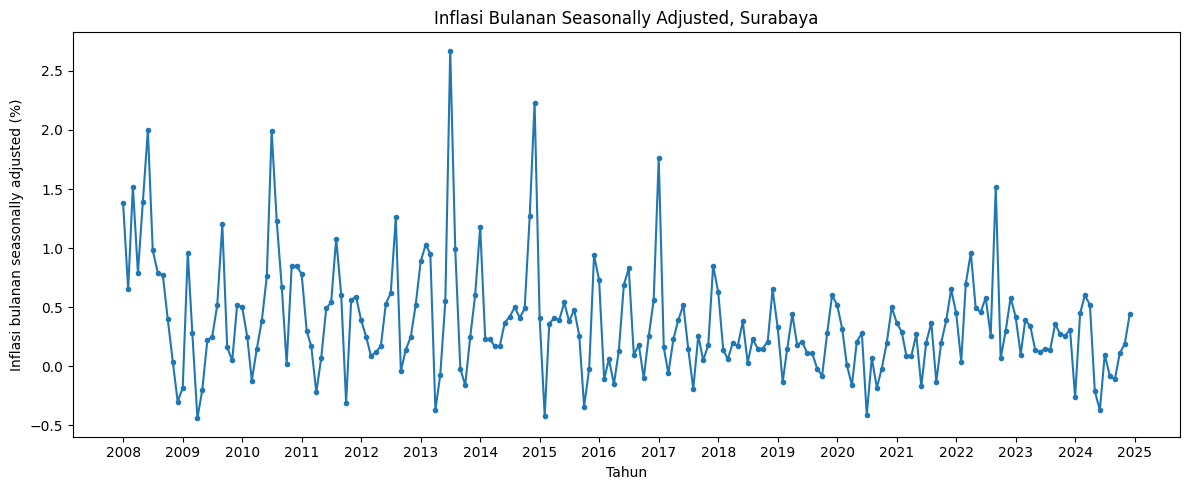

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

tahun = pd.to_numeric(df['Tahun'], errors='raise').astype(int)
bulan = df['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan.isna().any():
    raise ValueError(f"Unrecognized month names: {df.loc[bulan.isna(), 'Bulan'].unique()}")

df_plot = df.copy()
df_plot['Tanggal'] = pd.to_datetime({
    'year': tahun,
    'month': bulan,
    'day': 1
})
df_plot = df_plot.sort_values('Tanggal')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_plot['Tanggal'], df_plot['Bulanan'], marker='o', markersize=3)

ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi bulanan seasonally adjusted (%)')
ax.set_title('Inflasi Bulanan Seasonally Adjusted, Surabaya')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()